# Navigation target classifier: trained on ALL sessions
No holdout: this model is for deployment, not for measuring (use retrain_v3 numbers in the report).

**Runtime → T4 GPU, then Runtime → Restart session and run all.** Each run is saved to its own folder `MyDrive/tinyml/final/<date>_<time>/` (Stockholm time), so earlier models are never overwritten.

In [ ]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/tinyml'
!unzip -q -o {OUT}/data.zip -d /content/
DATA = '/content/data'

import os, glob, json
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras

CLASSES = ["pad_A", "pad_B", "pad_C", "pad_D", "pad_E", "no_target"]  # same order as v1!
IMG, ALPHA, BATCH, SEED = 128, 0.35, 32, 42 # 96
tf.keras.utils.set_random_seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Index all images (uses log.csv; falls back to file names if a day has no log)
rows = []
for day_dir in sorted(glob.glob(f'{DATA}/day_*')):
    day = day_dir.rsplit('_', 1)[-1]
    log = os.path.join(day_dir, 'log.csv')
    if os.path.exists(log):
        d = pd.read_csv(log, dtype={'session': str})
        d['path'] = day_dir + '/' + d['file']
    else:
        d = pd.DataFrame({'path': glob.glob(f'{day_dir}/*/*.jpg')})
        d['class'] = d.path.str.split('/').str[-2]
        d['session'] = d.path.str.split('/').str[-1].str.rsplit('_', n=1).str[0]
    d['day'] = day
    rows.append(d[['path', 'class', 'day', 'session']])
df = pd.concat(rows, ignore_index=True)
df = df[df.path.map(os.path.exists) & df['class'].isin(CLASSES)]
df['session'] = df.day + '_' + df.session.astype(str)
TEST_DAYS = ['D', 'E']  # held-out test days: never train on them
df = df[~df.day.isin(TEST_DAYS)]
assert not df.day.isin(TEST_DAYS).any()
print(df.groupby(['class', 'day']).size().unstack(fill_value=0))

day         A    C
class             
no_target  90  120
pad_A      90   90
pad_B      90   90
pad_C      90   90
pad_D      90   90
pad_E      90   90


In [ ]:
# 3. FINAL: every session goes into training (no holdout)
df['split'] = 'train'
print(df.groupby(['class', 'day']).size().unstack(fill_value=0))

day         A    C
class             
no_target  90  120
pad_A      90   90
pad_B      90   90
pad_C      90   90
pad_D      90   90
pad_E      90   90


In [ ]:
# 4. Datasets
def load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (IMG, IMG), antialias=True), label  # squash, same as the Pi

def make_ds(d, train=False):
    paths = np.array(d['path'].tolist())
    labels = np.array([CLASSES.index(c) for c in d['class']], dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

tr = df
va = df.sample(64, random_state=SEED)  # only so the code runs; these images are also in training
train_ds, val_ds = make_ds(tr, True), make_ds(va)


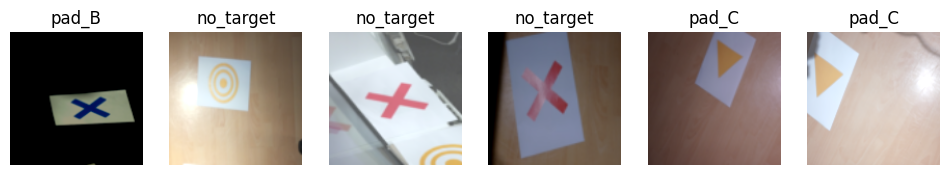

In [ ]:
# 5. Augmentation (tf.image, in the data pipeline) + model
def aug_one(img, label):
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, tf.int32))      # 0/90/180/270 deg
    img = tf.image.random_flip_left_right(img)
    size = tf.cast(tf.random.uniform([], 0.7, 1.0) * IMG, tf.int32)        # random zoom-in / shift
    img = tf.image.resize(tf.image.random_crop(img, [size, size, 3]), (IMG, IMG))
    img = tf.image.random_brightness(img, 0.25 * 255)
    img = tf.image.random_contrast(img, 0.75, 1.25)
    img = img * tf.random.uniform([3], 0.9, 1.1)                           # warm/cool light (per-channel gain)
    img = tf.clip_by_value(img, 0, 255) / 255.0                            # saturation/hue need 0..1
    img = tf.image.random_saturation(img, 0.7, 1.3)
    img = tf.image.random_hue(img, 0.03)                                   # small: colour is part of pad identity
    return tf.clip_by_value(img * 255.0, 0, 255), label

train_ds_aug = (tf.data.Dataset.from_tensor_slices(
                    (np.array(tr['path'].tolist()), np.array([CLASSES.index(c) for c in tr['class']], np.int32)))
                .shuffle(len(tr), seed=SEED)
                .map(load, num_parallel_calls=tf.data.AUTOTUNE)
                .map(aug_one, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH).prefetch(tf.data.AUTOTUNE))

tf.keras.backend.clear_session()
preprocess = keras.layers.Rescaling(1 / 127.5, offset=-1, name='preprocess')  # = mobilenet_v2.preprocess_input
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), alpha=ALPHA,
                                      include_top=False, weights='imagenet')
base.trainable = False
gap  = keras.layers.GlobalAveragePooling2D()
drop = keras.layers.Dropout(0.3)
head = keras.layers.Dense(len(CLASSES), activation='softmax', name='probs')

inp = keras.Input((IMG, IMG, 3))
train_model = keras.Model(inp, head(drop(gap(base(preprocess(inp), training=False)))))

img  = keras.Input((IMG, IMG, 3), name='image')
feat = base(preprocess(img), training=False)
infer_model = keras.Model(img, [head(gap(feat)), feat])  # 2 outputs: probs + feature map (CAM)

# Sanity check: what the model sees during training
import matplotlib.pyplot as plt
xa, ya = next(iter(train_ds_aug))
plt.figure(figsize=(12, 2.5))
for i in range(6):
    plt.subplot(1, 6, i + 1); plt.imshow(xa[i].numpy().astype('uint8')); plt.title(CLASSES[ya[i]]); plt.axis('off')
plt.show()

In [ ]:
NT = CLASSES.index('no_target')
neg_paths = tr.loc[tr['class'] == 'no_target', 'path'].tolist()

def tile_negative(path):
    """Random half-frame crop of a no_target image = what a pipeline tile sees."""
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    crop = tf.image.random_crop(img, [h // 2, w // 2, 3])
    return tf.image.resize(crop, (IMG, IMG)), tf.constant(NT, tf.int32)

full_ds = (tf.data.Dataset.from_tensor_slices(
               (np.array(tr['path'].tolist()), np.array([CLASSES.index(c) for c in tr['class']], np.int32)))
           .map(load, num_parallel_calls=tf.data.AUTOTUNE))
tile_ds = (tf.data.Dataset.from_tensor_slices(np.array(neg_paths))
           .map(tile_negative, num_parallel_calls=tf.data.AUTOTUNE))

train_ds_aug = (full_ds.concatenate(tile_ds)
                .shuffle(len(tr) + len(neg_paths), seed=SEED)
                .map(aug_one, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH).prefetch(tf.data.AUTOTUNE))
print("train images per epoch:", len(tr) + len(neg_paths), "| extra tile negatives:", len(neg_paths))

train images per epoch: 1320 | extra tile negatives: 210


In [ ]:
# 6. Stage 1: train the head (base frozen), lr = 1e-3, fixed 12 epochs
train_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('Stage 1 lr:', float(train_model.optimizer.learning_rate))
train_model.fit(train_ds_aug, epochs=12)

Stage 1 lr: 0.0010000000474974513
Epoch 1/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 21s 134ms/step - accuracy: 0.4477 - loss: 1.4394
Epoch 2/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7273 - loss: 0.7817
Epoch 3/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7977 - loss: 0.5904
Epoch 4/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8462 - loss: 0.4703
Epoch 5/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8697 - loss: 0.3999
Epoch 6/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8742 - loss: 0.3992
Epoch 7/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8886 - loss: 0.3327
Epoch 8/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8932 - loss: 0.3154
Epoch 9/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9061 - loss: 0.2960
Epoch 10/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9205 - loss: 0.2660
Epoch 11/12
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9038 - loss: 0.2842
Epoch 12/12
42/42 ━━━━━━━━━

In [ ]:
# 7. Stage 2: fine-tune the last 30 layers, lr = 1e-5, fixed 8 epochs
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:                                   # BatchNorm fix: keep BN frozen
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
train_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('Stage 2 lr:', float(train_model.optimizer.learning_rate))
train_model.fit(train_ds_aug, epochs=8)

Stage 2 lr: 9.999999747378752e-06
Epoch 1/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 21s 153ms/step - accuracy: 0.9242 - loss: 0.2526
Epoch 2/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9280 - loss: 0.2264
Epoch 3/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9303 - loss: 0.2360
Epoch 4/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.9273 - loss: 0.2259
Epoch 5/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9303 - loss: 0.2113
Epoch 6/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9333 - loss: 0.2081
Epoch 7/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9273 - loss: 0.2040
Epoch 8/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.9492 - loss: 0.1759


In [ ]:
# 8. Sanity check (NOT an evaluation: these images were used for training)
probs = infer_model.predict(make_ds(df), verbose=0)[0]
d = df.assign(ok=probs.argmax(1) == df['class'].map(CLASSES.index).to_numpy(), conf=probs.max(1))
print('Training-set accuracy per session (should be high everywhere):')
print(d.groupby(['class', 'session']).agg(acc=('ok', 'mean'), conf=('conf', 'mean')).round(2))

Training-set accuracy per session (should be high everywhere):
                              acc  conf
class     session                      
no_target A_20261012_200916  0.90  0.93
          A_20261012_202818  1.00  0.99
          A_20261012_204243  0.90  0.94
          C_20261018_213404  1.00  0.98
          C_20261018_213638  0.97  0.89
          C_20261018_213807  0.97  0.81
          C_20261018_213945  0.97  0.87
pad_A     A_20261012_195701  1.00  0.99
          A_20261012_201259  0.97  0.95
          A_20261012_203123  0.97  0.97
          C_20261018_210921  0.97  0.94
          C_20261018_211055  1.00  0.92
          C_20261018_211225  0.90  0.83
pad_B     A_20261012_195915  0.97  0.93
          A_20261012_201855  0.97  0.92
          A_20261012_203256  1.00  0.96
          C_20261018_211458  1.00  0.94
          C_20261018_211619  0.97  0.95
          C_20261018_211737  1.00  0.96
pad_C     A_20261012_200203  1.00  0.97
          A_20261012_202058  1.00  0.94
          A_20261

In [ ]:
# 9. Export to a NEW dated folder: MyDrive/tinyml/final/<date>_<time>/  (earlier runs stay untouched)
from datetime import datetime
from zoneinfo import ZoneInfo
RUN = datetime.now(ZoneInfo('Europe/Stockholm')).strftime('%Y-%m-%d_%H%M')
FINAL, n = f'{OUT}/final/{RUN}', 2
while os.path.exists(FINAL):            # same minute twice -> _2, _3, ...
    FINAL, n = f'{OUT}/final/{RUN}_{n}', n + 1
os.makedirs(FINAL)
infer_model.save(f'{FINAL}/landing_final.keras')
try:
    tflite = tf.lite.TFLiteConverter.from_keras_model(infer_model).convert()
except Exception as e:  # Keras 3 fallback
    print('from_keras_model failed, using SavedModel export:', e)
    infer_model.export('/content/landing_final_saved')
    tflite = tf.lite.TFLiteConverter.from_saved_model('/content/landing_final_saved').convert()
open(f'{FINAL}/landing_final.tflite', 'wb').write(tflite)
json.dump({"classes": CLASSES, "img": IMG, "alpha": ALPHA}, open(f'{FINAL}/landing_final.json', 'w'))
np.save(f'{FINAL}/cam_weights.npy', head.get_weights()[0])

# Verify: TFLite must give the same answers as Keras
it = tf.lite.Interpreter(model_content=tflite); it.allocate_tensors()
inp_d = it.get_input_details()[0]
out_d = next(o for o in it.get_output_details() if len(o['shape']) == 2)
x, _ = next(iter(make_ds(df.sample(8, random_state=1))))
diff = 0
for i in range(8):
    it.set_tensor(inp_d['index'], x[i:i+1].numpy().astype(np.float32)); it.invoke()
    diff = max(diff, np.abs(it.get_tensor(out_d['index'])[0] - infer_model.predict(x[i:i+1], verbose=0)[0][0]).max())
print('Max TFLite vs Keras difference:', diff, '-> OK' if diff < 1e-3 else '-> PROBLEM')
# What was trained, so runs can be told apart later (.txt, not .json: the Pi loads the first *.json it finds)
info = {"run": os.path.basename(FINAL), "classes": CLASSES, "img": IMG, "alpha": ALPHA,
        "train_images": len(tr), "days": sorted(df.day.unique().tolist()),
        "tile_negatives": 'neg_paths' in globals(), "stage1_epochs": 12, "stage2_epochs": 8,
        "tflite_vs_keras_max_diff": float(diff)}
json.dump(info, open(f'{FINAL}/run_info.txt', 'w'), indent=1)
d.groupby(['class', 'session']).agg(acc=('ok', 'mean'), conf=('conf', 'mean')).round(3).to_csv(f'{FINAL}/train_sanity.csv')
print('Saved to', FINAL, sorted(os.listdir(FINAL)))

Saved artifact at '/tmp/tmphxakq04k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 6), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4, 4, 1280), dtype=tf.float32, name=None)]
Captures:
  135631675203920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675203728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675206416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675207568: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Max TFLite vs Keras difference: 8.940697e-07 -> OK
Saved to /content/drive/MyDrive/tinyml/final/2026-10-25_1357 ['cam_weights.npy', 'landing_final.json', 'landing_final.keras', 'landing_final.tflite', 'run_info.txt', 'train_sanity.csv']


9 misclassified no_target images


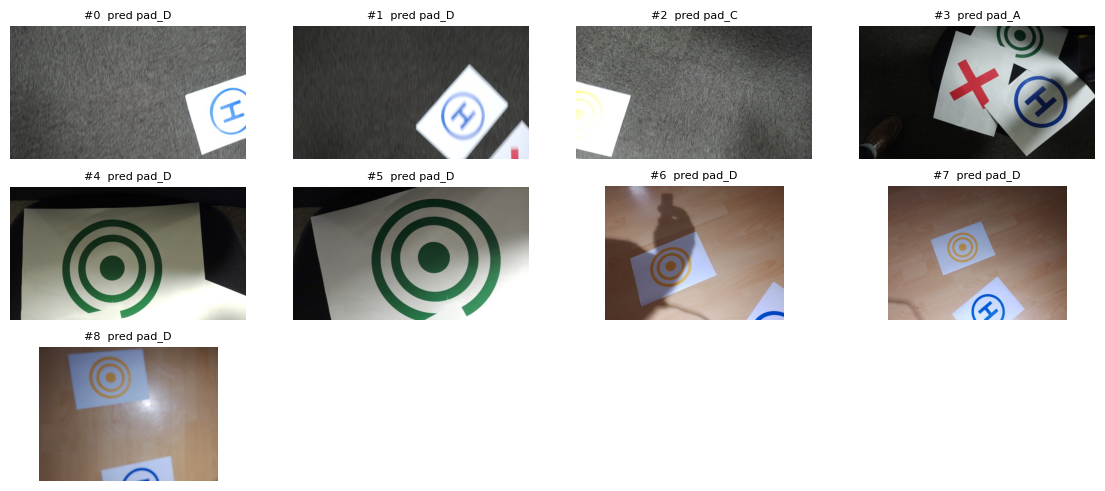

In [ ]:
nt = d[(d['class'] == 'no_target') & ~d.ok].reset_index(drop=True)
pred = [CLASSES[i] for i in probs[(df['class'] == 'no_target').to_numpy() & ~d.ok.to_numpy()].argmax(1)]
print(len(nt), 'misclassified no_target images')
import matplotlib.pyplot as plt
for start in range(0, len(nt), 16):
    plt.figure(figsize=(14, 8))
    for i in range(start, min(start + 16, len(nt))):
        plt.subplot(4, 4, i - start + 1); plt.imshow(plt.imread(nt.path[i])); plt.axis('off')
        plt.title(f'#{i}  pred {pred[i]}', fontsize=8)
    plt.show()

In [ ]:
# 10. RQ2 exports: float32 + int8 → FINAL
import shutil
SM = f'/content/sm_{IMG}'
infer_model.export(SM)                                   # works on Keras 2 and 3

def save(tfl, name):
    p = f'{FINAL}/model_{IMG}_{name}.tflite'
    open(p, 'wb').write(tfl); print(p, f'{os.path.getsize(p)/1024:.0f} KB'); return p

# float32 = the model cell 9 already verified
p32 = f'{FINAL}/model_{IMG}_f32.tflite'
shutil.copy(f'{FINAL}/landing_final.tflite', p32)
print(p32, f'{os.path.getsize(p32)/1024:.0f} KB')

# int8 calibration: full frames + tile-like crops, days A+C, no augmentation, 0-255
calib = tr.groupby('class', group_keys=False).apply(
    lambda g: g.sample(min(len(g), 150), random_state=SEED))
def rep_data():
    for p in calib['path']:
        x, _ = load(p, 0)
        yield [tf.cast(x, tf.float32)[None]]
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        h, w = tf.shape(img)[0], tf.shape(img)[1]
        t = tf.image.random_crop(img, [h // 3, w // 3, 3], seed=SEED)   # one 3x3-grid-sized tile
        yield [tf.cast(tf.image.resize(t, (IMG, IMG), antialias=True), tf.float32)[None]]

conv = tf.lite.TFLiteConverter.from_saved_model(SM)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = rep_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
p8 = save(conv.convert(), 'int8')                         # float I/O → infer.py unchanged

# int8 vs float32 check (training images: tests quantization only, not accuracy)
def run(path, x):
    it = tf.lite.Interpreter(model_path=path); it.allocate_tensors()
    it.set_tensor(it.get_input_details()[0]['index'], x); it.invoke()
    outs = [it.get_tensor(o['index']) for o in it.get_output_details()]
    return next(o for o in outs if o.ndim == 2), next(o for o in outs if o.ndim == 4)

agree, dp, corr = [], [], []
for p in df.sample(100, random_state=1)['path']:
    x = load(p, 0)[0].numpy()[None].astype(np.float32)
    (pf, ff), (pq, fq) = run(p32, x), run(p8, x)
    agree.append(pf.argmax() == pq.argmax()); dp.append(np.abs(pf - pq).max())
    corr.append(np.corrcoef(ff.ravel(), fq.ravel())[0, 1])
q = {'top1_agree': float(np.mean(agree)), 'max_dprob': float(np.max(dp)),
     'mean_dprob': float(np.mean(dp)), 'feat_corr': float(np.mean(corr))}
print(q)   # expect agree ≥ ~0.98, feat_corr ≥ ~0.95

info.update({'rq2_int8': q, 'calib_images': 2 * len(calib), 'stage2_trainable_layers': 30})
json.dump(info, open(f'{FINAL}/run_info.txt', 'w'), indent=1)

Saved artifact at '/content/sm_128'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 6), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4, 4, 1280), dtype=tf.float32, name=None)]
Captures:
  135631675203920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675203728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675205648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675206416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675204304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135631675207568: Te

/tmp/ipykernel_6875/1925636795.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  calib = tr.groupby('class', group_keys=False).apply(


/content/drive/MyDrive/tinyml/final/2026-10-25_1357/model_128_int8.tflite 636 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{'top1_agree': 1.0, 'max_dprob': 0.32323402166366577, 'mean_dprob': 0.03455442190170288, 'feat_corr': 0.8567975905770606}
